# Part 1: COCO Captions Dataset
## Select and preprocess your image–caption dataset. Choose a dataset (COCO Captions, Flickr30k, Conceptual Captions, or a curated LAION subset) and curate a working subset of roughly 1k–5k image–caption pairs. Apply consistent image resizing, normalization, and a caption-cleaning pipeline (length filters, deduplication, quality heuristics, optional content filter). Document license, domain coverage, and ethical considerations in a short dataset memo.

## 0. Install needed libraries

In [1]:
# Import libraries
!pip install pycocotools
!pip install fiftyone
!pip install --upgrade Pillow

You should consider upgrading via the '~/Desktop/P2/Rhea/NU Grad/IE 7615/ie7615-env/bin/python3 -m pip install --upgrade pip' command.
You should consider upgrading via the '~/Desktop/P2/Rhea/NU Grad/IE 7615/ie7615-env/bin/python3 -m pip install --upgrade pip' command.
You should consider upgrading via the '~/Desktop/P2/Rhea/NU Grad/IE 7615/ie7615-env/bin/python3 -m pip install --upgrade pip' command.


In [2]:
# Find the repo, move into the notebook folder, and pick a device
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/rasmussenj03/IE7615-Group3-Project2.git"
WORK_DIR = "Milestone 1"  # folder holding the notebooks, relative to the repo root
COLAB_USE_DRIVE = True  # False -> clone into /content (outputs are lost when the runtime ends)
COLAB_REPO_DIR = ("/content/drive/MyDrive/IE7615-Group3-Project2" if COLAB_USE_DRIVE
                  else "/content/IE7615-Group3-Project2")

if "google.colab" in sys.modules:
    if COLAB_USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
    if not Path(COLAB_REPO_DIR, "requirements.txt").is_file():
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")  # Colab secret holding a GitHub access token
        clone = subprocess.run(["git", "clone", "-q", REPO_URL.replace("https://", f"https://{token}@"),
                                COLAB_REPO_DIR], capture_output=True)
        if clone.returncode != 0:
            raise RuntimeError("git clone failed - check the GITHUB_TOKEN secret and repo access")
        subprocess.run(["git", "-C", COLAB_REPO_DIR, "remote", "set-url", "origin", REPO_URL])
    root = Path(COLAB_REPO_DIR)
    # Install the pinned packages (local runs use the .venv instead)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(root / "requirements.txt")],
                   check=True)
else:
    root = Path.cwd()
    while not (root / "requirements.txt").exists() and root != root.parent:
        root = root.parent

PROJECT_ROOT = root
os.chdir(PROJECT_ROOT / WORK_DIR)

import torch
if torch.cuda.is_available():
    device = "cuda"
    device_name = "cuda - " + torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    device = device_name = "mps"
else:
    device = device_name = "cpu"
print("Project root:", PROJECT_ROOT)
print("Working folder:", Path.cwd())
print("PyTorch", torch.__version__, "| device:", device_name)

Project root: IE7615-Group3-Project2
Working folder: IE7615-Group3-Project2/Milestone 1
PyTorch 2.8.0 | device: mps


## 1. Import COCO Captions Dataset using FiftyOne
### Here, we are using the FiftyOne library in order to download portions of the COCO Captions dataset, instead of needing to download the entireity of the dataset locally.

In [3]:
import re
import string

def clean_caption(text, min_words=3, max_words=40, blocked_terms=None):
    text = re.sub(r"\s+", " ", str(text)).strip()

    words = text.split()
    if not min_words <= len(words) <= max_words:
        return None

    if not re.search(r"[A-Za-z0-9]", text):
        return None

    # Reject URLs
    if re.search(r"https?://|www\.", text, flags=re.IGNORECASE):
        return None

    # Reject captions with unusually high punctuation
    punctuation_count = sum(char in string.punctuation for char in text)
    if punctuation_count / max(len(text), 1) > 0.25:
        return None

    # Optional case-insensitive blocked-term filter
    if blocked_terms:
        pattern = r"\b(?:" + "|".join(
            re.escape(term) for term in blocked_terms
        ) + r")\b"
        if re.search(pattern, text, flags=re.IGNORECASE):
            return None

    return text


def clean_and_deduplicate(captions, **kwargs):
    cleaned = []
    seen = set()

    for caption in captions:
        result = clean_caption(caption, **kwargs)
        if result is None:
            continue

        # Deduplicate case-insensitively, ignoring punctuation
        key = re.sub(r"[^\w\s]", "", result).casefold()
        key = re.sub(r"\s+", " ", key).strip()

        if key not in seen:
            seen.add(key)
            cleaned.append(result)

    return cleaned

In [4]:
# Load in the COCO dataset using FiftyOne
import fiftyone as fo
import fiftyone.zoo as foz
from pathlib import Path

# Download COCO into this project's dataset/ folder instead of ~/fiftyone
fo.config.dataset_zoo_dir = str(Path("dataset").resolve())

dataset = foz.load_zoo_dataset(
    "coco-2017",
    split="train",
    label_types=["detections"],
    max_samples=3000,
    shuffle=True,
    seed=42,
    drop_existing_dataset=True,  # rebuild from this project's dataset/ folder every run
)

# print("Samples:", len(dataset))
# print("Fields:", dataset.get_field_schema())

Found annotations at 'IE7615-Group3-Project2/Milestone 1/dataset/coco-2017/raw/instances_train2017.json'
Sufficient images already downloaded
Existing download of split 'train' is sufficient
Deleting existing dataset 'coco-2017-train-3000'
Loading 'coco-2017' split 'train'
 100% |███████████████| 3000/3000 [10.2s elapsed, 0s remaining, 285.3 samples/s]      
Dataset 'coco-2017-train-3000' created


In [5]:
import json
from collections import defaultdict
from PIL import Image
from torch.utils.data import Dataset

class COCODataset(Dataset):
    def __init__(self, fo_dataset, captions_json, transform=None):
        self.transform = transform
        captions_by_id = defaultdict(list)
        seen_by_id = defaultdict(set)
    
        with open(captions_json, "r", encoding="utf-8") as f:
            coco_data = json.load(f)
    
        # Clean and deduplicate each annotation once
        for ann in coco_data["annotations"]:
            text = clean_caption(
                ann.get("caption", ""),
                min_words=3,
                max_words=40,
            )
            if not text:
                continue
    
            image_id = int(ann["image_id"])
            key = text.casefold()
    
            if key not in seen_by_id[image_id]:
                seen_by_id[image_id].add(key)
                captions_by_id[image_id].append(text)
    
        captions_by_filename = {
            image_info["file_name"]: captions_by_id.get(image_info["id"], [])
            for image_info in coco_data["images"]
        }

        # COCO metadata for each image, used in the dataset memo's license section
        licenses = {lic["id"]: lic["name"] for lic in coco_data["licenses"]}
        info_by_filename = {
            image_info["file_name"]: {
                "image_id": image_info["id"],
                "file_name": image_info["file_name"],
                "license": licenses[image_info["license"]],
            }
            for image_info in coco_data["images"]
        }
    
        self.samples = []
        for sample in fo_dataset:
            filename = os.path.basename(sample.filepath)
            captions = captions_by_filename.get(filename, [])
            if captions:
                self.samples.append((sample.filepath, captions, info_by_filename[filename]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, captions, _ = self.samples[idx]

        with Image.open(path) as im:
            image = im.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, captions

In [6]:
from torchvision import transforms

# Resize and normalize the image
transform = transforms.Compose([
    transforms.Resize(512),
    transforms.CenterCrop(512),
    transforms.ToTensor(),
    # Stable Diffusion expects 512x512 images with values in [-1, 1]
    transforms.Normalize([0.5] * 3, [0.5] * 3),
])

In [7]:
print(dataset.get_field_schema().keys())

sample = dataset.first()
print(sample)
print(sample.filepath)

odict_keys(['id', 'filepath', 'tags', 'metadata', 'created_at', 'last_modified_at', 'ground_truth'])
<Sample: {
    'id': '6ade715ac0694ba1d5aff18b',
    'media_type': 'image',
    'filepath': 'IE7615-Group3-Project2/Milestone 1/dataset/coco-2017/train/data/000000514127.jpg',
    'tags': ['train'],
    'metadata': <ImageMetadata: {
        'size_bytes': None,
        'mime_type': None,
        'width': 640,
        'height': 427,
        'num_channels': None,
    }>,
    'created_at': datetime.datetime(2026, 10, 25, 21, 15, 6, 730000),
    'last_modified_at': datetime.datetime(2026, 10, 25, 21, 15, 6, 730000),
    'ground_truth': <Detections: {
        'detections': [
            <Detection: {
                'id': '6ade715ac0694ba1d5aff181',
                'attributes': {},
                'tags': [],
                'label': 'car',
                'bounding_box': [
                    0.08321875,
                    0.14156908665105386,
                    0.812109375,
             

## 2. Implement the Dataset + Verify

In [8]:
import urllib.request
import zipfile
from pathlib import Path

# Download the COCO caption annotations from cocodataset.org if not already present
captions_json = Path("dataset") / "captions_train2017.json"
if not captions_json.exists():
    captions_json.parent.mkdir(parents=True, exist_ok=True)
    zip_path = captions_json.parent / "annotations_trainval2017.zip"
    urllib.request.urlretrieve(
        "http://images.cocodataset.org/annotations/annotations_trainval2017.zip",
        zip_path,
    )
    with zipfile.ZipFile(zip_path) as z:
        captions_json.write_bytes(z.read("annotations/captions_train2017.json"))
    zip_path.unlink()

print("Captions file:", captions_json)

Captions file: dataset/captions_train2017.json


In [9]:
import os 
from pathlib import Path

# Implement the dataset 
captions_json = Path("dataset") / "captions_train2017.json"
coco_dataset = COCODataset(dataset, captions_json, transform)

In [10]:
import torch
from torch.utils.data import DataLoader

# Verify the dataset is working
def collate_fn(batch):
    images, captions = zip(*batch)
    return torch.stack(images), list(captions)

coco_dataloader = DataLoader(
    coco_dataset,
    batch_size=4,
    shuffle=True,
    collate_fn=collate_fn,
)

# coco_dataloader = DataLoader(coco_dataset, batch_size=4, shuffle=True)
for images, captions in coco_dataloader:
    print("Images shape:", images.shape)
    print("Captions:", captions)
    break

Images shape: torch.Size([4, 3, 512, 512])
Captions: [['A airplane coming in a for a landing on the water.', 'A plane seems to be getting ready to land in the water.', 'A small airplane with two large floaters underneath it flying over water.', 'A biplane gets ready to land on the water.', 'An airplane about to safely land in the water'], ['A long haired snowboarder poses standing with his board.', 'A young man posing with a snow board.', 'a male in a jersey holding a snow board.', 'a young man holds a snow board', 'A man holding a white snow board by some other kids'], ['A group of children with school bags looking out a window', 'A couple of kids looking out of a window on a subway car.', 'Two children staring out a window while on public transportation.', 'the passengers are looking out at the scenery as they pass by the area', 'Two young children look out of the window.'], ['Several skaters are skating and walking at a skate park.', 'Skaters watch a boy grind a handrail.', 'A man g

Images shape: torch.Size([4, 3, 512, 512])


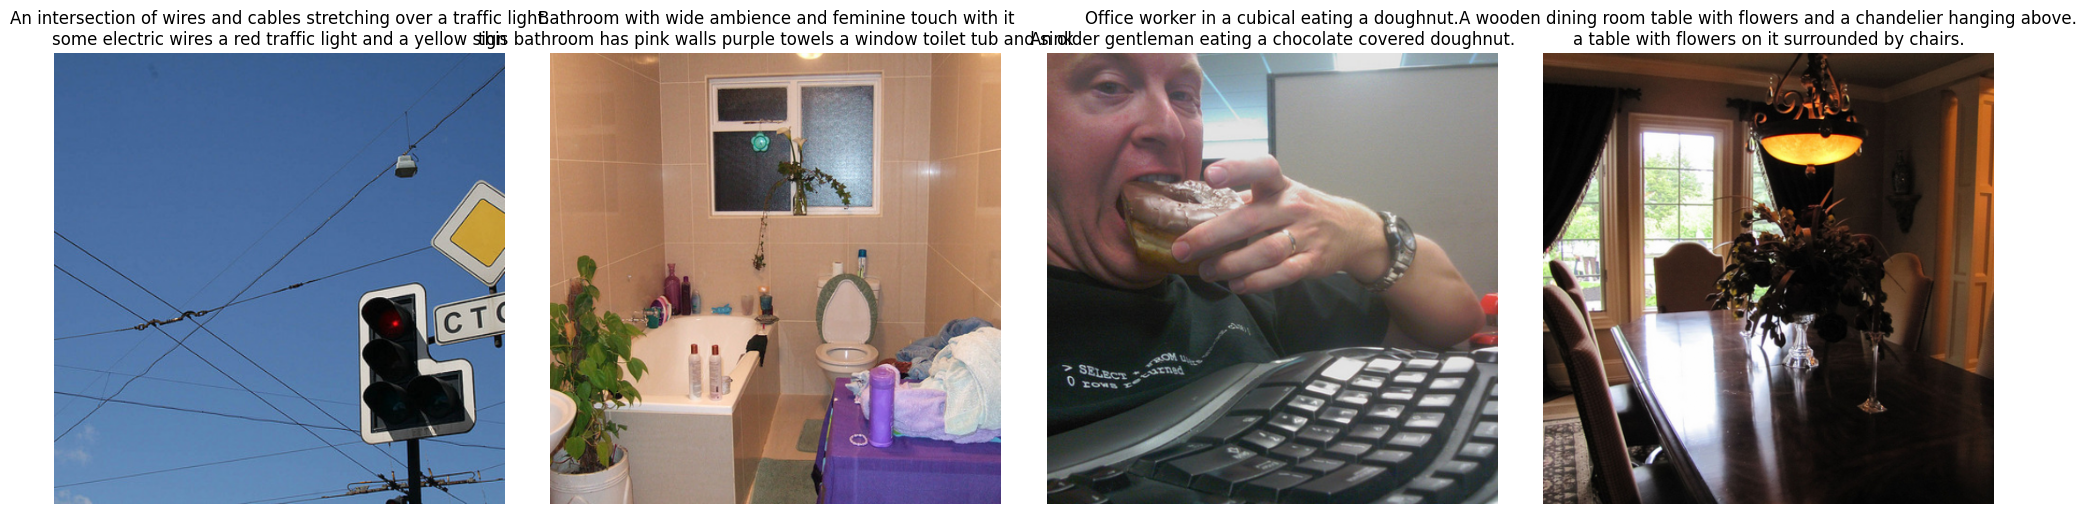

In [11]:
import matplotlib.pyplot as plt
import torch

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

for images, captions in coco_dataloader:
    print("Images shape:", images.shape)

    n = images.size(0)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
    if n == 1:
        axes = [axes]

    for i, ax in enumerate(axes):
        # Undo the [-1, 1] normalization
        image = (images[i].cpu() * 0.5 + 0.5).clamp(0, 1)
        image = image.permute(1, 2, 0).numpy()

        ax.imshow(image)
        ax.axis("off")
        ax.set_title("\n".join(captions[i][:2]))  # show up to 2 captions

    plt.tight_layout()
    plt.show()
    break

## 3. Save Dataset
### Here we are saving the dataset two-fold. First, we are saving locally. Second, we are also saving the TF dataset itself. 

In [12]:
import json
import numpy as np
import torch
from pathlib import Path
from PIL import Image

output_dir = Path("coco_export")
images_dir = output_dir / "images"
images_dir.mkdir(parents=True, exist_ok=True)

records = []

for i, (image, captions) in enumerate(coco_dataset):
    # Convert tensor to CPU
    image = image.detach().cpu()

    # Convert [C, H, W] -> [H, W, C]
    image = image.permute(1, 2, 0).numpy()

    # Undo the [-1, 1] normalization, then convert to uint8 RGB
    image = np.ascontiguousarray(
        (np.clip(image * 0.5 + 0.5, 0, 1) * 255).round().astype(np.uint8)
    )
    filename = f"{i:06d}.png"

    pil_image = Image.fromarray(image).convert("RGB")
    pil_image.save(images_dir / filename, format="PNG")
    
    records.append({
        "image": f"images/{filename}",
        "captions": captions,
        **coco_dataset.samples[i][2],
    })

# Save caption metadata
with open(output_dir / "labels.json", "w", encoding="utf-8") as f:
    json.dump(records, f, ensure_ascii=False, indent=2)

print(f"Saved {len(records)} images and captions to {output_dir.resolve()}")

Saved 3000 images and captions to IE7615-Group3-Project2/Milestone 1/coco_export


In [13]:
import torch

output = Path("dataset")

torch.save({
    "dataset": coco_dataset,
    "batch_size": coco_dataloader.batch_size,
    "num_workers": coco_dataloader.num_workers,
    "drop_last": coco_dataloader.drop_last,
}, (str(output) + "/dataloader_checkpoint.pt"))

In [14]:
# # To reload: 
# checkpoint = torch.load(
#     "dataset\dataloader_checkpoint.pt",
#     weights_only=False,  # only load files you created and trust
# )

# coco_dataset = checkpoint["dataset"]

# loader = torch.utils.data.DataLoader(
#     coco_dataset,
#     batch_size=checkpoint["batch_size"],
#     num_workers=checkpoint["num_workers"],
#     drop_last=checkpoint["drop_last"],
# )